In [1]:
import numpy as np
import torch
import torchvision.transforms.v2 as v2
from torchvision.datasets import FashionMNIST
import matplotlib.pyplot as plt

In [2]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True)
])

In [3]:
# download the dataset
full_train_dataset = FashionMNIST(
    root="./data",
    transform=transform,
    train=True,
    download=True
)
test_dataset = FashionMNIST(
    root="./data",
    transform=transform,
    train=False,
    download=True
)

class_to_idx = full_train_dataset.class_to_idx
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}
idx_to_class

100.0%
100.0%
100.0%
100.0%


{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

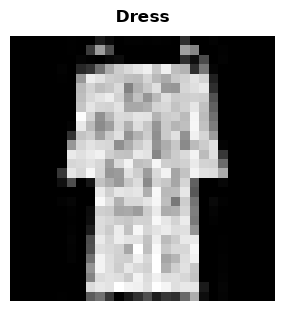

In [4]:
# draw a sample data point
def draw(data_point):
    img, label = data_point
    fig, ax = plt.subplots(layout="constrained", figsize=(3, 3))
    ax.imshow(img.squeeze(0).numpy(), cmap="gray")
    ax.axis("off")
    ax.set_title(idx_to_class[label], pad=10.0, fontsize="large", fontweight="bold")
    plt.show()

data_point = test_dataset[33]
draw(data_point)

In [5]:
# divide the full_train_dataset into train and val datasets
lengths = len(full_train_dataset)-len(test_dataset), len(test_dataset)
train_dataset, val_dataset = torch.utils.data.dataset.random_split(
    full_train_dataset,
    lengths,
    #generator=torch.Generator().manual_seed(763) # for reproducibility
)
len(train_dataset), len(val_dataset)

(50000, 10000)

In [6]:
len(train_dataset), len(val_dataset), len(test_dataset)

(50000, 10000, 10000)

In [7]:
for i in range(15):
    img, label = train_dataset[i]
    print(label)

8
8
8
2
1
3
8
5
7
5
4
8
2
4
3


In [8]:
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [9]:
# seperate the train data points according to its classes to inspect
data_points = [[] for _ in range(10)]
for img, label in train_dataset:
    data_points[label].append(img)

In [10]:
for i, v in enumerate(data_points):
    print(f"{i}: {len(v)}")

0: 5008
1: 5001
2: 5006
3: 4980
4: 5040
5: 5004
6: 5019
7: 4994
8: 4997
9: 4951


In [11]:
def visuilize_class(cls):
    idx = class_to_idx[cls]
    imgs = data_points[idx]
    
    fig, axs = plt.subplots(nrows=1, ncols=10, figsize=(15, 1.8))
    for i, ax in enumerate(axs):
        ax.imshow(imgs[i].squeeze().numpy(), cmap="gray")
        ax.axis("off")
    fig.suptitle(cls, fontsize=14, fontweight="bold")
    plt.show()

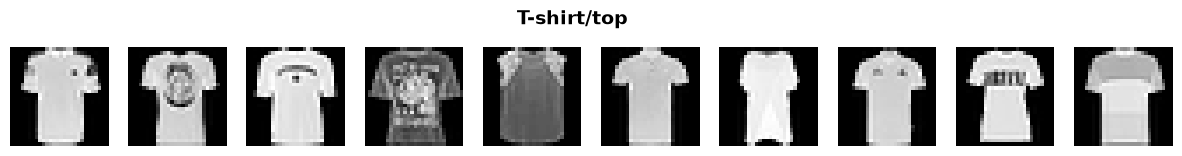

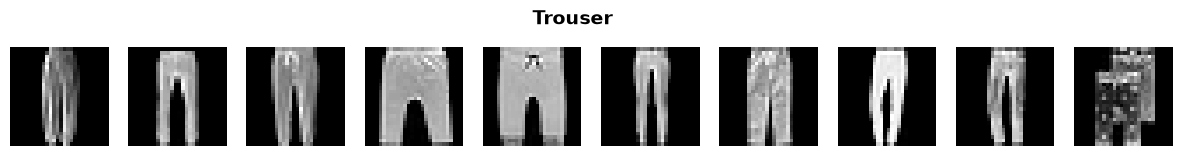

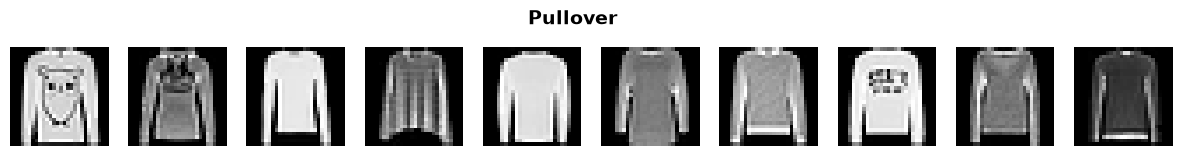

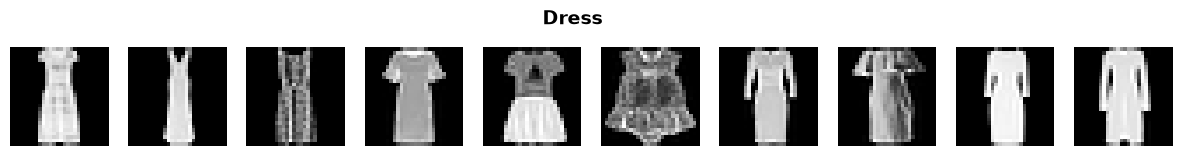

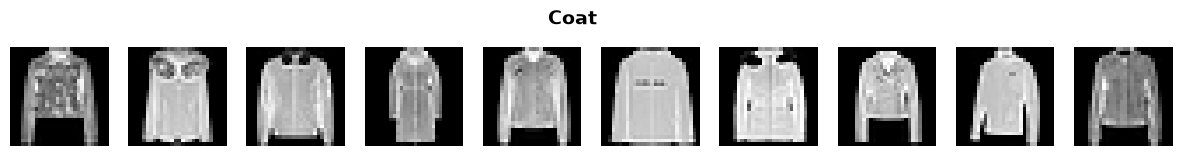

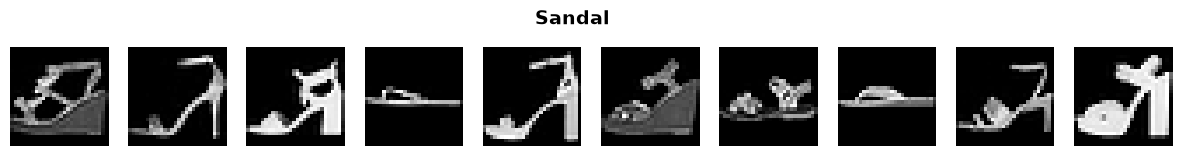

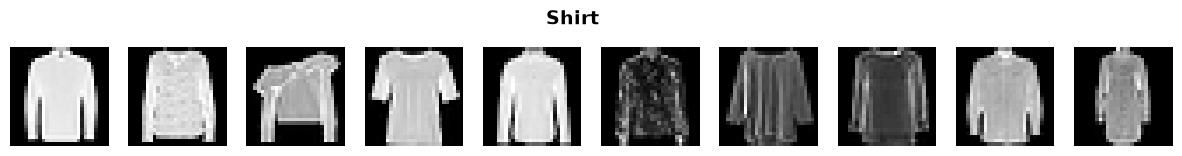

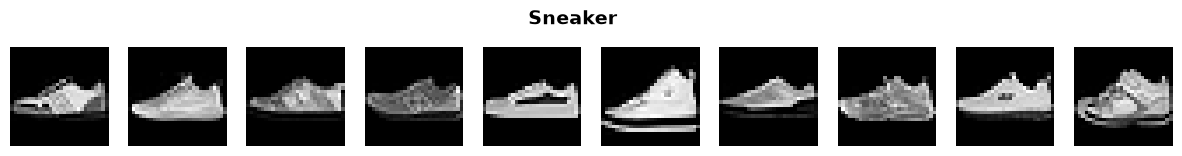

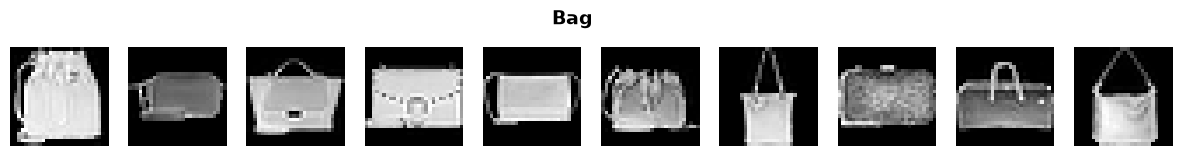

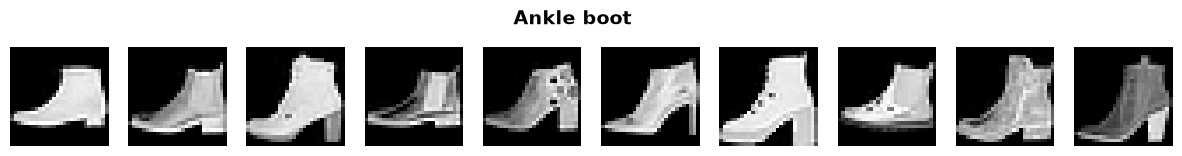

In [12]:
for cls in class_to_idx:
    visuilize_class(cls)

In [13]:
# let's make a data loader
train_dataloader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=10,
    shuffle=True,
)

In [14]:
def visuilize_batch(batch):
    fig, axs = plt.subplots(nrows=1, ncols=len(batch[1]), figsize=(15, 1.8))
    for img, label, ax in zip(*batch, axs):
        ax.imshow(img.squeeze(0).numpy(), cmap="gray")
        ax.axis("off")
        ax.set_title(idx_to_class[label.item()], fontsize=12, fontweight="bold")
    plt.show()

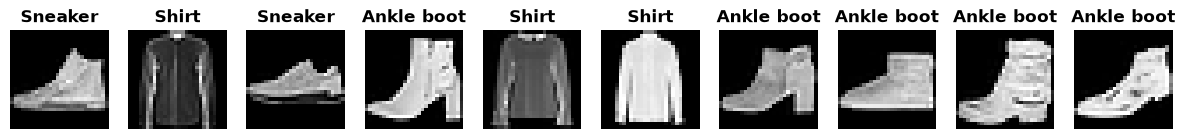

In [15]:
batch = next(iter(train_dataloader))
visuilize_batch(batch)